# 03 — Results and sensitivity analysis

Reproduces every result, table and figure of the final report (`docs/final_report/`). It reuses the model of notebook 02 (`%run`) instead of copying it.

**All results are obtained with synthetic data** (notebook 01) and do not describe any real hospital.

Contents:

1. Setup and helpers
2. Baseline results: January 2027, December 2026 and August 2027, scenarios A and B
3. Sensitivity analysis
   - 3.1 Workforce size and monthly duty limit
   - 3.2 Seniority mix
   - 3.3 Duties versus ordinary activity (priorities inside $f_1$, ward requirement $PL_d$)
   - 3.4 Fairness over several months (memory and fairness metric)
   - 3.5 What each objective contributes (and weighted versus lexicographic objective)
4. Summary of the findings

Figure labels are in Spanish because the figures are used in the report. Running the whole notebook takes about 11 minutes with an academic Gurobi licence.

## 1. Setup and helpers

Set parameter Username
Set parameter LicenseID to value 2860142
Academic license - for non-commercial use only - expires 2027-09-03
1352 variables (758 binary), 1393 constraints, runtime 0.3 s
f1_unmet: 1.0001e-06
f2_requests: 0
f3_fairness: 14.7784
f4_patterns: 1


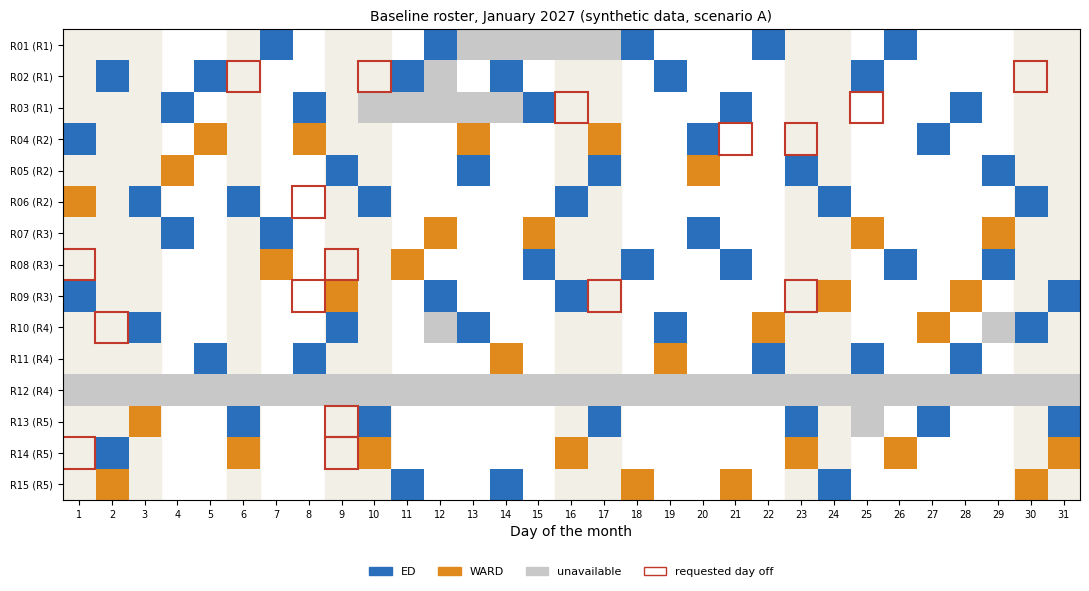

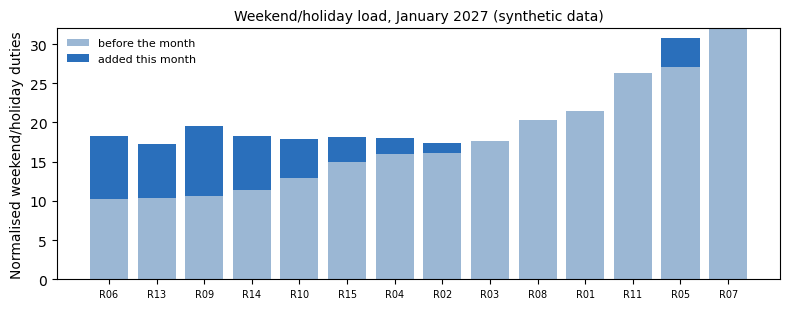

In [1]:
%run 02_baseline_model.ipynb
plt.close("all")

import itertools
import time

ANALYSIS_SEED = 2026  # random choice of the residents removed in Section 3.1
pd.set_option("display.width", 200)

# Colours (validated categorical palette, fixed order) and recessive chrome.
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100", "grey": "#9a9893"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2, "lines.markersize": 5,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

# KPI names (computed by kpis() from the roster, notebook 02).
UNC, SEN, ORD, BELOW, F1 = ("uncovered duty positions", "missing seniors", "missing residents for ordinary activity",
                            "duties below training minimum", "f1 unmet requirements")
REQ, F2, F3, F4 = ("requests violated / total", "f2 weighted violated requests",
                   "f3 weekend/holiday load range after the month", "f4 alternate-day patterns")
MONTHS = {"jan2027_base": "Enero 2027", "dec2026_christmas": "Diciembre 2026", "aug2027_summer": "Agosto 2027"}

### Instance transformations

Every sensitivity experiment builds a modified copy of an instance; the model itself is never changed.

- `with_cap(inst, cap)`: monthly maximum $G^{\max}_r = \min(G^{\max}_r, \text{cap})$ (stricter local agreements).
- `with_PL(inst, pl)`: residents needed for ordinary activity on every working day, $PL_d = pl$.
- `add_residents(inst, k)`: $k$ extra residents, fully available all month, with residency years cycling R3, R2, R4, R5, R1, no requests, not on duty in the previous month, $H_r$ equal to the median normalised history of the service and $\Phi_r = 1$. They are an optimistic assumption: a real new resident would also take vacations.
- `drop_residents(inst, residents)` (notebook 02): removes residents.

In [2]:
def copy_instance(inst, suffix=""):
    out = {k: (v.copy() if isinstance(v, pd.DataFrame) else v) for k, v in inst.items()}
    out["name"] = inst["name"] + suffix
    return out


def with_cap(inst, cap):
    out = copy_instance(inst, f"_cap{cap}")
    res = out["residents"]
    res["G_max"] = res["G_max"].clip(upper=cap)
    res["G_min"] = np.minimum(res["G_min"], res["G_max"])
    return out


def with_PL(inst, pl):
    out = copy_instance(inst, f"_PL{pl}")
    out["calendar"]["PL"] = np.where(out["calendar"]["is_F"], 0, pl)
    return out


def add_residents(inst, k, years=(3, 2, 4, 5, 1)):
    out = copy_instance(inst, f"_plus{k}")
    if k == 0:
        return out
    cal, res, cfg = inst["calendar"], inst["residents"], inst["meta"]["config"]
    min_year = {g: spec["min_year"] for g, spec in cfg["duty_types"].items()}
    active = res[res["Phi"] > 0]
    H_new = int(round((active["H"] / active["Phi"]).median()))
    new_res, elig, avail = [], [], []
    for i in range(k):
        r, year = f"X{i + 1:02d}", years[i % len(years)]
        new_res.append({"resident": r, "year": year, "senior": year >= cfg["senior_min_year"], "first_year": year == 1,
                        "days_available": len(cal), "G_min": cfg["G_min"], "G_max": int(res["G_max"].max()),
                        "H": H_new, "Phi": 1.0})
        for d, is_F in zip(cal["day"], cal["is_F"]):
            avail.append({"resident": r, "day": d, "available": 1, "ROT": int(not is_F), "reason": ""})
            for g, y0 in min_year.items():
                elig.append({"resident": r, "day": d, "duty": g, "E": int(year >= y0)})
    out["residents"] = pd.concat([res, pd.DataFrame(new_res)], ignore_index=True)
    out["eligibility"] = pd.concat([inst["eligibility"], pd.DataFrame(elig)], ignore_index=True)
    out["availability"] = pd.concat([inst["availability"], pd.DataFrame(avail)], ignore_index=True)
    return out


def regime(inst, scenario, cap):
    # Scenario B applies its own limit inside build_model (at most four 17-hour duties).
    return inst if scenario == "B" or cap >= 7 else with_cap(inst, cap)


def structural_ward_gap(inst):
    # Residents missing for ordinary activity even if nobody were on duty: sum_d max(0, PL_d - sum_r ROT_rd).
    s = index_instance(inst)
    return sum(max(0, s["PL"][d] - sum(s["ROT"].get((r, d), 0) for r in s["R"])) for d in s["L"])

### Objective variants

`run(inst, scenario, variant, fairness)` builds the model of notebook 02, optionally changes one level of the lexicographic objective, solves it, **validates the roster** (every hard constraint, checked independently of Gurobi) and returns the roster and its KPIs.

| `variant` | Change with respect to the model of the report |
|---|---|
| `lex` | None: $\operatorname{lex\,min}(f_1, f_2, f_3, f_4)$ |
| `duties_first` | $f_1$ split in two levels: first duty positions, seniors and training minima; then residents for ordinary activity |
| `no_requests` / `no_patterns` | $f_2$ / $f_4$ removed |
| `weighted` | Weighted sum $1000 f_1 + 100 f_2 + 10 f_3 + f_4$ |

| `fairness` | Level $f_3$ |
|---|---|
| `range` | $e^{\max} - e^{\min}$ (model of the report) |
| `mad` | Mean absolute deviation of the normalised loads from their mean, linearised with $a_r \ge L_r - \bar L$, $a_r \ge \bar L - L_r$ |
| `none` | Removed |

Gurobi's hierarchical solver applies one time limit to all levels. For the multi-month simulation (Section 3.4) `solve_sequential` solves the levels one at a time, each with its own time limit, fixing the value reached by every level before optimising the next one.

In [3]:
def fairness_loads(m):
    # Normalised weekend/holiday load L_r = (H_r + sum_{d in F} y_rd) / Phi_r, for r in R^F.
    s, x = m._sets, m._vars["x"]
    return {r: (s["H"][r] + gp.quicksum(x[r, d, g] for d in s["F"] for g in s["G"] if (r, d, g) in x)) * (1.0 / s["Phi"][r])
            for r in s["R_F"]}


def set_variant(m, variant):
    v = m._vars
    if variant in ("lex", "weighted"):
        pass
    elif variant == "duties_first":
        m.setObjectiveN(v["h"].sum() + v["hS"].sum() + v["hG"].sum(), index=0, priority=10, name="f1a_duties")
        m.setObjectiveN(v["hP"].sum(), index=4, priority=9, name="f1b_ordinary")
    elif variant == "no_requests":
        m.setObjectiveN(gp.LinExpr(), index=1, priority=3, name="f2_removed")
    elif variant == "no_patterns":
        m.setObjectiveN(gp.LinExpr(), index=3, priority=1, name="f4_removed")
    else:
        raise ValueError(variant)


def set_fairness(m, fairness):
    if fairness == "range":
        return
    if fairness == "none":
        m.setObjectiveN(gp.LinExpr(), index=2, priority=2, name="f3_removed")
        return
    if fairness == "mad":
        loads = fairness_loads(m)
        mean = gp.quicksum(loads.values()) * (1.0 / len(loads))
        a = m.addVars(list(loads), name="a")
        for r, L in loads.items():
            m.addConstr(a[r] >= L - mean, name=f"mad_pos[{r}]")
            m.addConstr(a[r] >= mean - L, name=f"mad_neg[{r}]")
        m.setObjectiveN(a.sum() * (1.0 / len(loads)), index=2, priority=2, name="f3_mad")
        return
    raise ValueError(fairness)


def solve_sequential(m, level_time=20):
    # Lexicographic optimisation level by level, each level with its own time limit.
    m.update()
    levels = []
    for i in range(m.NumObj):
        m.Params.ObjNumber = i
        levels.append((m.ObjNPriority, m.getObjective(i)))
    m.NumObj = 0
    m.Params.MIPGap = 0
    for _, expr in sorted(levels, key=lambda t: -t[0]):
        m.setObjective(expr, GRB.MINIMIZE)
        m.Params.TimeLimit = level_time
        m.optimize()
        if m.SolCount == 0:
            raise RuntimeError(f"No solution found (status {m.Status}).")
        m.addConstr(expr <= m.ObjVal + 1e-6)
    x = m._vars["x"]
    return pd.DataFrame([k for k in x if x[k].X > 0.5], columns=["resident", "day", "duty"])


def run(inst, scenario="A", variant="lex", fairness="range", sequential=False):
    m = build_model(inst, scenario, objective="weighted" if variant == "weighted" else "lex")
    set_variant(m, variant)
    set_fairness(m, fairness)
    t0 = time.time()
    roster = solve_sequential(m) if sequential else solve(m)
    runtime = time.time() - t0
    assert validate(roster, inst, scenario).sum() == 0, "hard constraint violated"
    k = kpis(roster, inst, scenario)
    k["runtime (s)"] = round(runtime, 2)
    return roster, k

## 2. Baseline results

The three months under both regulatory scenarios. Scenario B is approximated as in notebook 02: every duty is a 17-hour module, so constraint (10) becomes at most $4 + C_r$ duties per month with $C_r = 0$, and residents on duty on a working day do not count for ordinary activity.

In [4]:
def capacity(inst):
    res, dem = inst["residents"], inst["demand"]
    return pd.Series({
        "residents available for duties": int((res["G_max"] > 0).sum()),
        "duty positions (sum N)": int(dem["N"].sum()),
        "weekend/holiday days": int(inst["calendar"]["is_F"].sum()),
        "nominal capacity (sum G_max)": int(res["G_max"].sum()),
        "residents on vacation at least one day": int((inst["availability"]["reason"] == "vacation").groupby(
            inst["availability"]["resident"]).any().sum()),
        "structural ordinary-activity gap": structural_ward_gap(inst),
        "requests": len(inst["requests"]),
    })


instances = {name: load_instance(name) for name in MONTHS}
display(pd.DataFrame({MONTHS[n]: capacity(i) for n, i in instances.items()}))

baseline, base_rosters = {}, {}
for name, inst in instances.items():
    for scen in ["A", "B"]:
        m = build_model(inst, scen)
        m.update()
        base_rosters[name, scen], k = run(inst, scen)
        k["variables"], k["binary variables"], k["constraints"] = m.NumVars, m.NumIntVars, m.NumConstrs
        baseline[f"{MONTHS[name]} ({scen})"] = k
baseline = pd.DataFrame(baseline)
baseline.to_csv(TAB_DIR / "final_baseline_months.csv")
baseline

,Enero 2027,Diciembre 2026,Agosto 2027
residents available for duties,14,14,14
duty positions (sum N),93,93,93
weekend/holiday days,12,11,9
nominal capacity (sum G_max),98,98,98
residents on vacation at least one day,2,6,8
structural ordinary-activity gap,0,0,7
requests,17,12,21


,Enero 2027 (A),Enero 2027 (B),Diciembre 2026 (A),Diciembre 2026 (B),Agosto 2027 (A),Agosto 2027 (B)
uncovered duty positions,0,37,5,37,24,47
missing seniors,0,0,0,2,0,4
missing residents for ordinary activity,0,0,1,0,15,19
duties below training minimum,0,0,0,0,0,0
f1 unmet requirements,0,37,6,39,39,70
requests violated / total,0 / 17,0 / 17,0 / 12,0 / 12,0 / 21,0 / 21
f2 weighted violated requests,0,0,0,0,0,0
weekend/holiday load range before the month,21.71,21.71,27.54,27.54,10.25,10.25
f3 weekend/holiday load range after the month,14.78,17.14,23.08,23.08,9.78,9.78
f4 alternate-day patterns,1,0,0,0,0,0


### Figures of the baseline month (January 2027, scenario A)

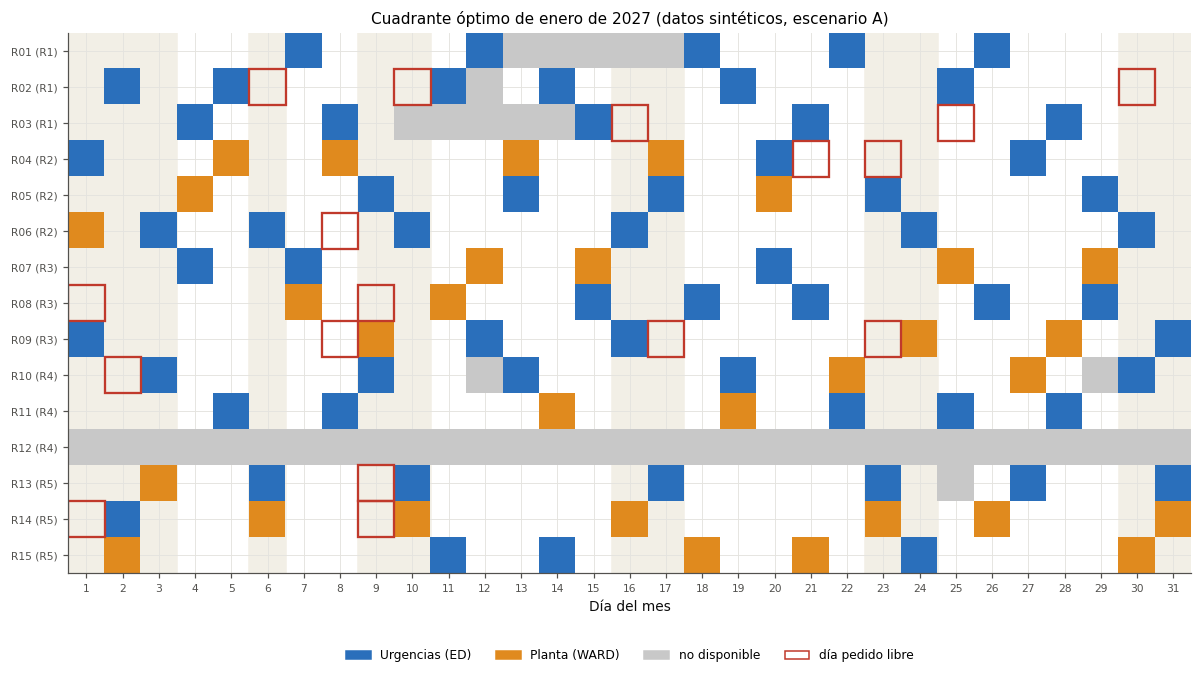

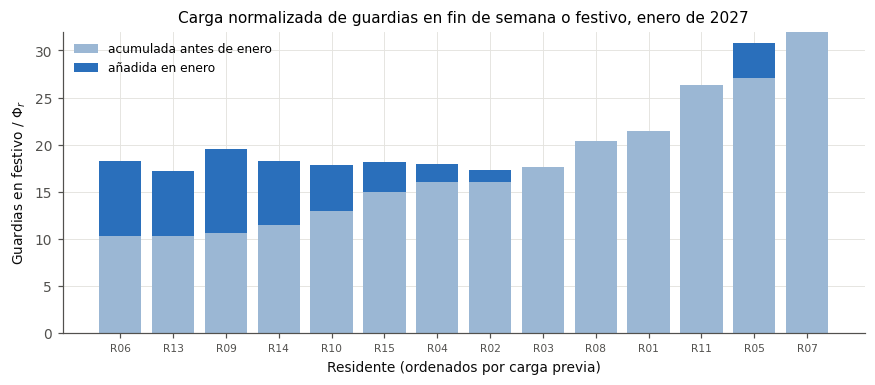

In [5]:
ROSTER_ES = {"ED": "Urgencias (ED)", "WARD": "Planta (WARD)", "unavailable": "no disponible",
             "requested day off": "día pedido libre"}


def relabel(fig, title, xlabel=None, ylabel=None, legend_map=ROSTER_ES):
    ax = fig.axes[0]
    ax.set_title(title, fontsize=10)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if ax.get_legend():
        for t in ax.get_legend().get_texts():
            t.set_text(legend_map.get(t.get_text(), t.get_text()))
    return fig


jan = instances["jan2027_base"]
fig = plot_roster(base_rosters["jan2027_base", "A"], jan, "")
relabel(fig, "Cuadrante óptimo de enero de 2027 (datos sintéticos, escenario A)", "Día del mes")
fig.savefig(FIG_DIR / "final_roster_jan2027.png")

fig = plot_fairness(base_rosters["jan2027_base", "A"], jan, "")
relabel(fig, "Carga normalizada de guardias en fin de semana o festivo, enero de 2027", ylabel="Guardias en festivo / $\\Phi_r$",
        legend_map={"before the month": "acumulada antes de enero", "added this month": "añadida en enero"})
fig.axes[0].set_xlabel("Residente (ordenados por carga previa)")
fig.savefig(FIG_DIR / "final_fairness_jan2027.png")

### Where are the gaps of August?

Uncovered positions and missing residents for ordinary activity per day (scenario A), together with the number of residents available that day.

In [6]:
def daily_gaps(roster, inst, scenario="A"):
    s = index_instance(inst)
    y = y_table(roster, s)
    cal = inst["calendar"].set_index("day")
    assigned = roster.groupby("day").size().reindex(s["D"], fill_value=0)
    need = pd.Series({d: sum(s["N"][d, g] for g in s["G"]) for d in s["D"]})
    present = {d: sum(s["ROT"].get((r, d), 0) * (1 - y.get((r, d - 1), 0) - (y.get((r, d), 0) if scenario == "B" else 0))
                      for r in s["R"]) for d in s["L"]}
    return pd.DataFrame({
        "weekday": cal["weekday"], "weekend/holiday": cal["is_F"],
        "residents available": inst["availability"].groupby("day")["available"].sum(),
        "uncovered positions": need - assigned,
        "missing for ordinary activity": pd.Series({d: max(0, s["PL"][d] - present[d]) for d in s["L"]}).reindex(s["D"], fill_value=0),
    })


aug = instances["aug2027_summer"]
aug_daily = daily_gaps(base_rosters["aug2027_summer", "A"], aug)
aug_daily.T

,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
weekday,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue,...,Sun,Mon,Tue,Wed,Thu,Fri,Sat,Sun,Mon,Tue
weekend/holiday,True,False,False,False,False,False,True,True,False,False,...,True,False,False,False,False,False,True,True,False,False
residents available,13,11,11,11,11,11,10,10,10,8,...,10,10,12,13,13,13,14,14,14,14
uncovered positions,0,1,1,1,1,0,0,2,1,1,...,2,0,0,0,0,0,0,0,0,0
missing for ordinary activity,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


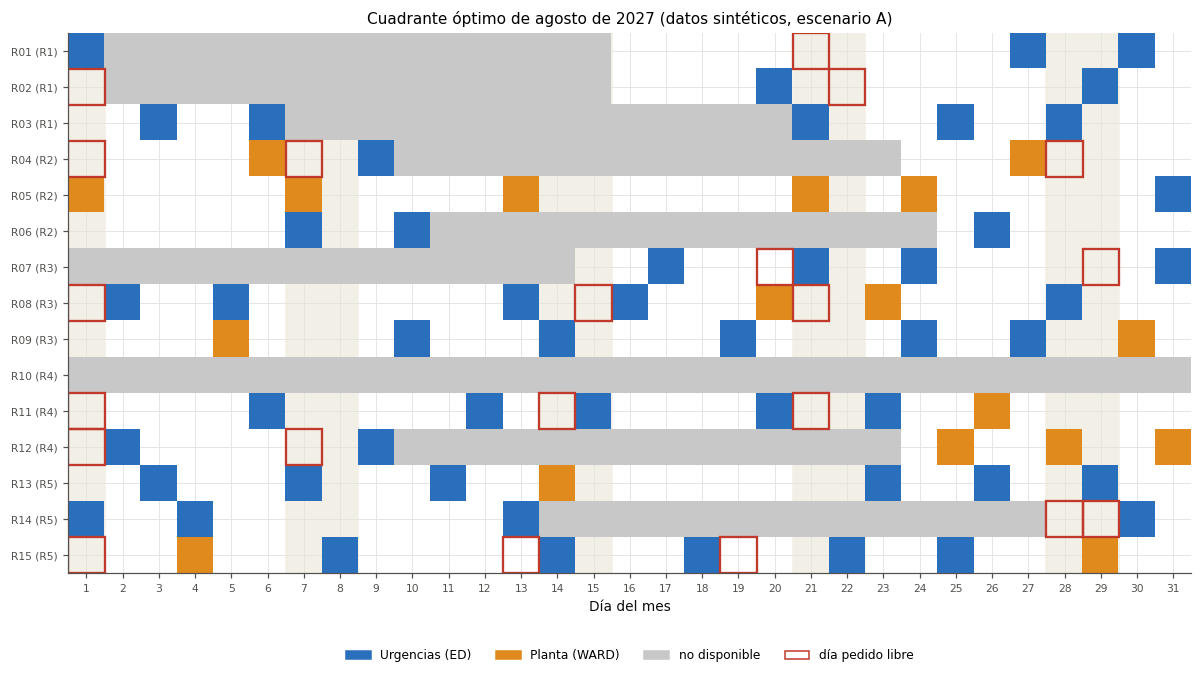

In [7]:
fig = plot_roster(base_rosters["aug2027_summer", "A"], aug, "")
relabel(fig, "Cuadrante óptimo de agosto de 2027 (datos sintéticos, escenario A)", "Día del mes")
fig.savefig(FIG_DIR / "final_roster_aug2027.png")

## 3. Sensitivity analysis

### 3.1 Workforce size and monthly duty limit

How many residents does the service need to cover each month under each regime? For every month and regime the workforce is reduced (1 to 4 residents removed, 5 random draws each) and enlarged (0 to 12 synthetic residents added). Regimes:

- A with the legal maximum of 7 duties per month (RD 1146/2006);
- A with stricter local agreements: at most 6 or 5 duties;
- B (RD 951/2026), approximated by at most four 17-hour duties.

In [8]:
REGIMES = [("A", 7, "A: máx. 7 guardias/mes"), ("A", 6, "A: máx. 6 guardias/mes"),
           ("A", 5, "A: máx. 5 guardias/mes"), ("B", 4, "B: RD 951/2026 (máx. 4 × 17 h)")]
rng = np.random.default_rng(ANALYSIS_SEED)
curve = []
for name, inst in instances.items():
    active = list(inst["residents"].loc[inst["residents"]["G_max"] > 0, "resident"])
    removals = {k: [list(rng.choice(active, size=k, replace=False)) for _ in range(5)] for k in range(1, 5)}
    for scen, cap, label in REGIMES:
        for k, draws in removals.items():
            for rep, out in enumerate(draws):
                _, kp = run(regime(drop_residents(inst, out), scen, cap), scen)
                curve.append({"month": name, "regime": label, "change": -k, "draw": rep, "staff": len(active) - k,
                              "uncovered": kp[UNC], "seniors": kp[SEN], "ordinary": kp[ORD], "f1": kp[F1]})
        for k in range(0, 13):
            _, kp = run(add_residents(regime(inst, scen, cap), k), scen)
            curve.append({"month": name, "regime": label, "change": k, "draw": 0, "staff": len(active) + k,
                          "uncovered": kp[UNC], "seniors": kp[SEN], "ordinary": kp[ORD], "f1": kp[F1]})
            if kp[F1] == 0:  # adding residents can never increase f1
                for kk in range(k + 1, 13):
                    curve.append({"month": name, "regime": label, "change": kk, "draw": 0, "staff": len(active) + kk,
                                  "uncovered": 0, "seniors": 0, "ordinary": 0, "f1": 0})
                break
curve = pd.DataFrame(curve)
curve.to_csv(TAB_DIR / "final_staffing_curve.csv", index=False)
curve.groupby(["month", "regime", "staff"])["f1"].agg(["mean", "min", "max"]).unstack("staff").round(1)

mean                                                          ... max                              
staff                                                10     11     12    13    14    15    16    17    18    19  ...  17  18  19  20 21 22 23 24 25 26
month             regime                                                                                         ...                                  
aug2027_summer    A: máx. 5 guardias/mes          101.6   88.6   73.8  51.4  39.0  24.0  16.0   8.0   3.0   0.0  ...   8   3   0   0  0  0  0  0  0  0
                  A: máx. 6 guardias/mes           96.6   84.4   70.6  50.2  39.0  24.0  13.0   5.0   2.0   0.0  ...   5   2   0   0  0  0  0  0  0  0
                  A: máx. 7 guardias/mes           95.8   83.4   70.6  50.2  39.0  24.0  13.0   5.0   2.0   0.0  ...   5   2   0   0  0  0  0  0  0  0
                  B: RD 951/2026 (máx. 4 × 17 h)  128.0  116.2  104.0  83.0  70.0  53.0  37.0  27.0  21.0  17.0  ...  27  21  17  13  9  5  1  0  0  0
dec2026_christmas A: máx. 5 guardias/mes           63.8   49.8   37.4  29.8  23.0  18.0  13.0   8.0   3.0   0.0  ...   8   3   0   0  0  0  0  0  0  0
                  A: máx. 6 guardias/mes           56.6   38.8   25.4  16.8   9.0   3.0   0.0   0.0   0.0   0.0  ...   0   0   0   0  0  0  0  0  0  0
                  A: máx. 7 guardias/mes           56.0   36.4   18.0   9.6   6.0   2.0   0.0   0.0   0.0   0.0  ...   0   0   0   0  0  0  0  0  0  0
                  B: RD 951/2026 (máx. 4 × 17 h)   89.2   71.0   55.0  44.8  39.0  33.0  29.0  25.0  21.0  17.0  ...  25  21  17  13  9  5  1  0  0  0
jan2027_base      A: máx. 5 guardias/mes           48.6   41.4   33.2  28.0  23.0  18.0  13.0   8.0   3.0   0.0  ...   8   3   0   0  0  0  0  0  0  0
                  A: máx. 6 guardias/mes           41.6   29.0   21.0  15.0   9.0   3.0   0.0   0.0   0.0   0.0  ...   0   0   0   0  0  0  0  0  0  0
                  A: máx. 7 guardias/mes           41.2   24.2    9.0   2.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   0   0   0   0  0  0  0  0  0  0
                  B: RD 951/2026 (máx. 4 × 17 h)   72.4   57.8   48.8  42.2  37.0  33.0  29.0  25.0  21.0  17.0  ...  25  21  17  13  9  5  1  0  0  0

[12 rows x 51 columns]

Minimum number of residents (available for duties) needed to meet **all** requirements ($f_1 = 0$), and needed to cover all duty positions with enough seniors if ordinary activity may be reduced (variant `duties_first`).

In [9]:
def min_extra(inst, scen, cap, variant="lex", target=lambda k: k[F1] == 0, k_max=14):
    for k in range(0, k_max + 1):
        _, kp = run(add_residents(regime(inst, scen, cap), k), scen, variant=variant)
        if target(kp):
            return k
    return np.nan


rows = []
for name, inst in instances.items():
    active = int((inst["residents"]["G_max"] > 0).sum())
    for scen, cap, label in REGIMES:
        k_all = min_extra(inst, scen, cap)
        k_duties = min_extra(inst, scen, cap, "duties_first", lambda kp: kp[UNC] + kp[SEN] == 0)
        positions = int(inst["demand"]["N"].sum())
        rows.append({"month": MONTHS[name], "regime": label, "residents now": active,
                     "lower bound ceil(positions / cap)": int(np.ceil(positions / cap)),
                     "needed: all requirements": active + k_all, "needed: duties only": active + k_duties,
                     "extra: all requirements": k_all, "extra: duties only": k_duties})
min_staff = pd.DataFrame(rows)
min_staff.to_csv(TAB_DIR / "final_min_staff.csv", index=False)
min_staff

,month,regime,residents now,lower bound ceil(positions / cap),needed: all requirements,needed: duties only,extra: all requirements,extra: duties only
0,Enero 2027,A: máx. 7 guardias/mes,14,14,14,14,0,0
1,Enero 2027,A: máx. 6 guardias/mes,14,16,16,16,2,2
2,Enero 2027,A: máx. 5 guardias/mes,14,19,19,19,5,5
3,Enero 2027,B: RD 951/2026 (máx. 4 × 17 h),14,24,24,24,10,10
4,Diciembre 2026,A: máx. 7 guardias/mes,14,14,16,14,2,0
5,Diciembre 2026,A: máx. 6 guardias/mes,14,16,16,16,2,2
6,Diciembre 2026,A: máx. 5 guardias/mes,14,19,19,19,5,5
7,Diciembre 2026,B: RD 951/2026 (máx. 4 × 17 h),14,24,24,24,10,10
8,Agosto 2027,A: máx. 7 guardias/mes,14,14,19,14,5,0
9,Agosto 2027,A: máx. 6 guardias/mes,14,16,19,16,5,2


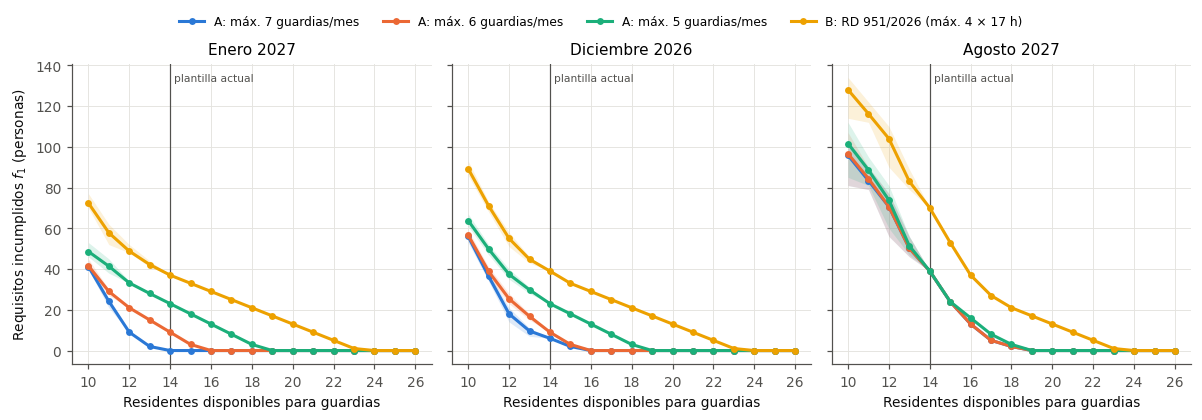

In [10]:
REG_COLORS = dict(zip([r[2] for r in REGIMES], [C["blue"], C["orange"], C["aqua"], C["yellow"]]))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, (name, title) in zip(axes, MONTHS.items()):
    sub = curve[curve["month"] == name]
    now = int((instances[name]["residents"]["G_max"] > 0).sum())
    ax.axvline(now, color=INK2, lw=0.8)
    ax.text(now + 0.2, 0.97, "plantilla actual", transform=ax.get_xaxis_transform(), fontsize=7, color=INK2, va="top")
    for label in REG_COLORS:
        g = sub[sub["regime"] == label].groupby("staff")["f1"].agg(["mean", "min", "max"])
        ax.fill_between(g.index, g["min"], g["max"], color=REG_COLORS[label], alpha=0.15, lw=0)
        ax.plot(g.index, g["mean"], color=REG_COLORS[label], marker="o", ms=3.5, label=label)
    ax.set_title(title)
    ax.set_xlabel("Residentes disponibles para guardias")
    ax.set_xticks(range(10, 27, 2))
axes[0].set_ylabel("Requisitos incumplidos $f_1$ (personas)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(FIG_DIR / "final_staffing_vs_regime.png")

### 3.2 Seniority mix

Two residents of the same residency year are removed (every pair), January and August 2027, scenario A. If the result does not depend on the year removed, the binding resource is the total number of duties, not seniority.

In [11]:
rows = []
for name in ["jan2027_base", "aug2027_summer"]:
    inst = instances[name]
    res = inst["residents"]
    for year in range(1, 6):
        pool = list(res.loc[(res["year"] == year) & (res["G_max"] > 0), "resident"])
        for pair in itertools.combinations(pool, 2):
            _, kp = run(drop_residents(inst, list(pair)), "A")
            rows.append({"month": MONTHS[name], "year removed": f"R{year}", "pair": "+".join(pair),
                         "uncovered": kp[UNC], "seniors": kp[SEN], "ordinary": kp[ORD], "f1": kp[F1]})
composition = pd.DataFrame(rows)
composition.to_csv(TAB_DIR / "final_composition.csv", index=False)
composition.groupby(["month", "year removed"])[["uncovered", "seniors", "ordinary", "f1"]].agg(["mean", "max"])

uncovered     seniors       ordinary             f1    
                               mean max    mean max       mean max       mean max
month       year removed                                                         
Agosto 2027 R1            32.000000  34     0.0   0  24.333333  28  56.333333  57
            R2            33.666667  35     0.0   0  30.333333  35  64.000000  67
            R3            34.333333  35     0.0   0  35.333333  42  69.666667  77
            R4            34.000000  34     0.0   0  33.000000  33  67.000000  67
            R5            32.333333  35     0.0   0  38.000000  42  70.333333  77
Enero 2027  R1             9.000000   9     0.0   0   0.000000   0   9.000000   9
            R2             9.000000   9     0.0   0   0.000000   0   9.000000   9
            R3             9.000000   9     0.0   0   0.000000   0   9.000000   9
            R4             9.000000   9     0.0   0   0.000000   0   9.000000   9
            R5             9.000000   9     0.0   0   0.000000   0   9.000000   9

### 3.3 Duties versus ordinary activity

$f_1$ adds uncovered duty positions and residents missing for ordinary activity with the same weight. Every duty on the eve of a working day creates a post-call resident (*saliente*) who is absent the next morning, so both requirements compete for the same people. We compare the model with the variant that covers duties first, and vary the ward requirement $PL_d$.

In [12]:
cases = {"Enero 2027, 3 residentes menos": drop_residents(instances["jan2027_base"], ["R15", "R08", "R05"]),
         "Diciembre 2026": instances["dec2026_christmas"], "Agosto 2027": instances["aug2027_summer"]}
rows = []
for case, inst in cases.items():
    for variant, label in [("lex", "Pesos iguales en $f_1$ (modelo)"), ("duties_first", "Guardias primero")]:
        _, kp = run(inst, "A", variant=variant)
        rows.append({"case": case, "variant": label, "uncovered": kp[UNC], "seniors": kp[SEN], "ordinary": kp[ORD],
                     "f1": kp[F1], "requests violated": kp[REQ], "f3": kp[F3], "f4": kp[F4]})
priority_f1 = pd.DataFrame(rows)
priority_f1.to_csv(TAB_DIR / "final_duties_vs_ordinary.csv", index=False)

rows = []
for scen in ["A", "B"]:
    for pl in range(7, 13):
        _, kp = run(with_PL(instances["jan2027_base"], pl), scen)
        rows.append({"scenario": scen, "PL": pl, "uncovered": kp[UNC], "ordinary": kp[ORD], "f1": kp[F1]})
pl_sens = pd.DataFrame(rows)
pl_sens.to_csv(TAB_DIR / "final_ordinary_PL.csv", index=False)
display(priority_f1)
pl_sens.pivot(index="PL", columns="scenario", values=["uncovered", "ordinary"])

,case,variant,uncovered,seniors,ordinary,f1,requests violated,f3,f4
0,"Enero 2027, 3 residentes menos",Pesos iguales en $f_1$ (modelo),20,0,5,25,0 / 15,14.78,1
1,"Enero 2027, 3 residentes menos",Guardias primero,16,0,9,25,0 / 15,14.78,1
2,Diciembre 2026,Pesos iguales en $f_1$ (modelo),5,0,1,6,0 / 12,23.08,0
3,Diciembre 2026,Guardias primero,0,0,6,6,0 / 12,23.08,0
4,Agosto 2027,Pesos iguales en $f_1$ (modelo),24,0,15,39,0 / 21,9.78,0
5,Agosto 2027,Guardias primero,0,0,39,39,0 / 21,9.78,16


uncovered     ordinary    
scenario         A   B        A   B
PL                                 
7                0  37        0   0
8                0  37        0   0
9                0  37        0   0
10               1  37        0   0
11               5  38        1   1
12              19  40        6  13

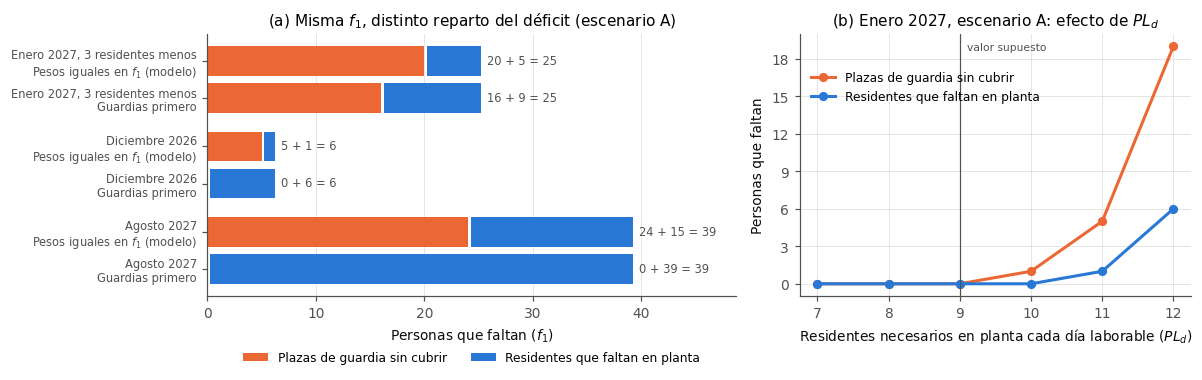

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.35, 1]})
labels, unc, ordn = [], [], []
for case in cases:
    for _, row in priority_f1[priority_f1["case"] == case].iterrows():
        labels.append(f"{case}\n{row['variant']}")
        unc.append(row["uncovered"] + row["seniors"])
        ordn.append(row["ordinary"])
yy = np.arange(len(labels))[::-1] + np.repeat([0.6, 0.3, 0.0], 2)
ax1.barh(yy, unc, height=0.8, color=C["orange"], label="Plazas de guardia sin cubrir")
ax1.barh(yy, ordn, left=np.array(unc) + 0.25, height=0.8, color=C["blue"], label="Residentes que faltan en planta")
for y_, u, o in zip(yy, unc, ordn):
    ax1.text(u + o + 0.8, y_, f"{u} + {o} = {u + o}", va="center", fontsize=7.5, color=INK2)
ax1.set_yticks(yy, labels, fontsize=7.5)
ax1.set_xlabel("Personas que faltan ($f_1$)")
ax1.set_xlim(0, max(np.array(unc) + np.array(ordn)) * 1.25)
ax1.grid(axis="y", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax1.set_title("(a) Misma $f_1$, distinto reparto del déficit (escenario A)")

for col, color, label in [("uncovered", C["orange"], "Plazas de guardia sin cubrir"),
                          ("ordinary", C["blue"], "Residentes que faltan en planta")]:
    g = pl_sens[pl_sens["scenario"] == "A"]
    ax2.plot(g["PL"], g[col], color=color, marker="o", label=label)
ax2.axvline(9, color=INK2, lw=0.8)
ax2.text(9.1, 0.97, "valor supuesto", transform=ax2.get_xaxis_transform(), fontsize=7, color=INK2, va="top")
ax2.set_xlabel("Residentes necesarios en planta cada día laborable ($PL_d$)")
ax2.set_ylabel("Personas que faltan")
ax2.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax2.legend(loc="upper left", bbox_to_anchor=(0, 0.9))
ax2.set_title("(b) Enero 2027, escenario A: efecto de $PL_d$")
fig.tight_layout()
fig.savefig(FIG_DIR / "final_duties_vs_ordinary.png")

### 3.4 Fairness over several months

Five consecutive months (January to May 2027) are rostered one after the other. After each month the history is updated with the roster just produced:

- $H_r \leftarrow H_r + \sum_{d \in \mathcal{F}} y_{rd}$;
- $\Phi_r \leftarrow \bigl((k-1)\,\Phi_r + a_r\bigr)/k$, where $k$ is the number of months of the reference period up to the new month and $a_r$ is the fraction of the new month during which $r$ is available;
- $Y_{r,-1}$ and $Y_{r,0}$ are the duties of the last two days of the month just rostered.

Four policies are compared:

1. **Range with memory** — the model of the report;
2. **Mean absolute deviation with memory** — alternative fairness metric;
3. **Range without memory** — each month is balanced on its own ($H_r = 0$, $\Phi_r$ = availability of the current month);
4. **No fairness criterion** — $f_3$ removed.

Every policy is evaluated with the **true** cumulative normalised load $(H_r + \sum_{d \in \mathcal{F}} y_{rd}) / \Phi_r$ of every resident with $\Phi_r > 0$. The levels are solved one by one with 20 s each (`solve_sequential`); the policy without memory reaches that limit at level $f_3$ (many symmetric solutions), the other policies solve every level to optimality.

In [14]:
ROLLING = ["jan2027_base", "feb2027", "mar2027", "apr2027", "may2027"]
POLICIES = {"Rango con memoria (modelo)": ("range", True), "Desviación media con memoria": ("mad", True),
            "Rango sin memoria": ("range", False), "Sin criterio de equidad": ("none", True)}


def months_in_reference_period(inst):
    cfg = inst["meta"]["config"]
    y0, m0 = cfg["reference_start"]
    return (cfg["year"] - y0) * 12 + cfg["month"] - m0 + 1


def load_stats(load):
    return {"range": load.max() - load.min(), "mad": (load - load.mean()).abs().mean()}


def rolling_simulation(fairness, memory):
    state, prev, rows = None, None, []
    for name in ROLLING:
        inst = copy_instance(load_instance(name))
        res = inst["residents"]
        avail_frac = (res["days_available"] / len(inst["calendar"])).values
        if state is None:  # January: history of the instance
            state = res.set_index("resident")[["H", "Phi"]].astype(float)
            rows.append({"month": "inicio", **load_stats((state["H"] / state["Phi"])[state["Phi"] > 0])})
        else:
            k = months_in_reference_period(inst)
            state = pd.DataFrame({"H": state["H"] + prev_F, "Phi": (state["Phi"] * (k - 1) + avail_frac) / k})
            roster_prev, n_prev = prev
            last = roster_prev[roster_prev["day"] >= n_prev - 1]
            inst["previous_month"] = pd.DataFrame({"resident": last["resident"].values,
                                                   "day": (last["day"] - n_prev).values, "on_duty": 1})
        res["H"] = state["H"].values if memory else 0
        res["Phi"] = state["Phi"].values if memory else avail_frac
        roster, kp = run(inst, "A", fairness=fairness, sequential=True)
        F_days = set(inst["calendar"].loc[inst["calendar"]["is_F"], "day"])
        prev_F = roster[roster["day"].isin(F_days)].groupby("resident").size().reindex(state.index, fill_value=0)
        load = ((state["H"] + prev_F) / state["Phi"])[state["Phi"] > 0]
        rows.append({"month": name, **load_stats(load), "f1": kp[F1], "f2": kp[F2], "f4": kp[F4],
                     "runtime (s)": kp["runtime (s)"]})
        prev = (roster, len(inst["calendar"]))
    return pd.DataFrame(rows)


rolling = pd.concat({p: rolling_simulation(*cfg) for p, cfg in POLICIES.items()}, names=["policy"]).reset_index(level=0)
rolling.to_csv(TAB_DIR / "final_fairness_rolling.csv", index=False)
rolling.pivot(index="month", columns="policy", values=["range", "mad"]).reindex(["inicio"] + ROLLING).round(2)

range                                                                                               mad                                               \
policy       Desviación media con memoria Rango con memoria (modelo) Rango sin memoria Sin criterio de equidad Desviación media con memoria Rango con memoria (modelo) Rango sin memoria   
month                                                                                                                                                                                      
inicio                              21.71                      21.71             21.71                   21.71                         6.32                       6.32              6.32   
jan2027_base                        16.00                      14.78             23.06                   24.35                         4.03                       4.42              6.24   
feb2027                             15.25                      11.14             22.52                   22.57                         2.85                       3.11              6.21   
mar2027                              8.43                       7.54             23.27                   22.16                         1.48                       1.55              6.50   
apr2027                              7.37                       7.26             25.70                   24.01                         1.16                       1.16              6.50   
may2027                              3.53                       3.53             26.08                   23.66                         0.48                       0.48              6.46   

                                      
policy       Sin criterio de equidad  
month                                 
inicio                          6.32  
jan2027_base                    6.30  
feb2027                         6.09  
mar2027                         5.71  
apr2027                         5.67  
may2027                         5.70

f1                                                                                                f2                                               \
policy       Desviación media con memoria Rango con memoria (modelo) Rango sin memoria Sin criterio de equidad Desviación media con memoria Rango con memoria (modelo) Rango sin memoria   
month                                                                                                                                                                                      
jan2027_base                          0.0                        0.0               0.0                     0.0                          0.0                        0.0               0.0   
feb2027                               0.0                        0.0               0.0                     0.0                          0.0                        0.0               0.0   
mar2027                               0.0                        0.0               0.0                     0.0                          0.0                        0.0               0.0   
apr2027                               0.0                        0.0               0.0                     0.0                          0.0                        0.0               0.0   
may2027                               0.0                        0.0               0.0                     0.0                          0.0                        0.0               0.0   

                                                               f4                                                                                       runtime (s)                             \
policy       Sin criterio de equidad Desviación media con memoria Rango con memoria (modelo) Rango sin memoria Sin criterio de equidad Desviación media con memoria Rango con memoria (modelo)   
month                                                                                                                                                                                            
jan2027_base                     0.0                          1.0                        1.0               0.0                     0.0                         1.37                       0.29   
feb2027                          0.0                          0.0                        0.0               0.0                     0.0                         2.92                       0.32   
mar2027                          0.0                          3.0                        0.0               0.0                     0.0                        35.99                       0.58   
apr2027                          0.0                          0.0                        0.0               0.0                     0.0                        13.11                       0.42   
may2027                          0.0                          0.0                        0.0               0.0                     0.0                         3.75                       0.54   

                                                        
policy       Rango sin memoria Sin criterio de equidad  
month                                                   
jan2027_base             20.32                    0.19  
feb2027                  20.26                    0.18  
mar2027                  20.30                    0.19  
apr2027                  20.31                    0.17  
may2027                  20.26                    0.20

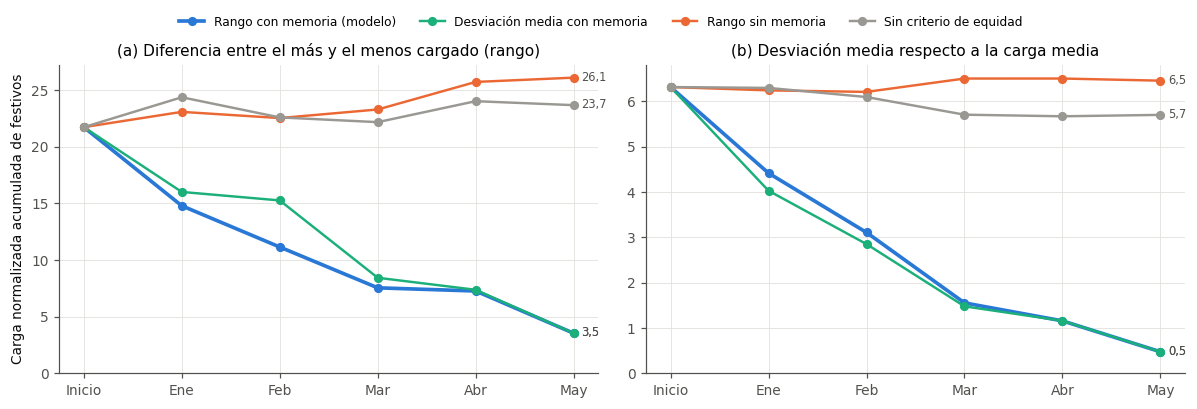

In [15]:
display(rolling.pivot(index="month", columns="policy", values=["f1", "f2", "f4", "runtime (s)"]).reindex(ROLLING))

MONTH_ES = ["Inicio", "Ene", "Feb", "Mar", "Abr", "May"]
POL_COLORS = dict(zip(POLICIES, [C["blue"], C["aqua"], C["orange"], C["grey"]]))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric, title in [(axes[0], "range", "(a) Diferencia entre el más y el menos cargado (rango)"),
                          (axes[1], "mad", "(b) Desviación media respecto a la carga media")]:
    for pol in POLICIES:
        g = rolling[rolling["policy"] == pol].set_index("month").reindex(["inicio"] + ROLLING)
        ax.plot(range(len(g)), g[metric], color=POL_COLORS[pol], marker="o", label=pol,
                lw=2.4 if pol.endswith("(modelo)") else 1.6)
        ax.annotate(f"{g[metric].iloc[-1]:.1f}".replace(".", ","), (len(g) - 1, g[metric].iloc[-1]), xytext=(5, 0),
                    textcoords="offset points", va="center", fontsize=7.5, color=INK2)
    ax.set_xticks(range(len(MONTH_ES)), MONTH_ES)
    ax.set_title(title)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("Carga normalizada acumulada de festivos")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
fig.savefig(FIG_DIR / "final_fairness_rolling.png")

### 3.5 What each objective contributes

Each lower-priority goal is removed in turn (all else equal), and the lexicographic objective is compared with the weighted sum $1000 f_1 + 100 f_2 + 10 f_3 + f_4$.

In [16]:
VARIANTS = [("lex", "range", "Modelo (lexicográfico)"), ("no_requests", "range", "Sin $f_2$ (peticiones)"),
            ("lex", "none", "Sin $f_3$ (equidad)"), ("no_patterns", "range", "Sin $f_4$ (día sí, día no)"),
            ("weighted", "range", "Suma ponderada")]
rows = []
for name, inst in instances.items():
    for variant, fairness, label in VARIANTS:
        _, kp = run(inst, "A", variant=variant, fairness=fairness)
        rows.append({"month": MONTHS[name], "variant": label, "f1": kp[F1], "uncovered": kp[UNC], "ordinary": kp[ORD],
                     "requests violated": kp[REQ], "f2": kp[F2], "f3": kp[F3], "f4": kp[F4], "runtime (s)": kp["runtime (s)"]})
objective_value = pd.DataFrame(rows)
objective_value.to_csv(TAB_DIR / "final_objective_variants.csv", index=False)
objective_value

,month,variant,f1,uncovered,ordinary,requests violated,f2,f3,f4,runtime (s)
0,Enero 2027,Modelo (lexicográfico),0,0,0,0 / 17,0,14.78,1,0.32
1,Enero 2027,Sin $f_2$ (peticiones),0,0,0,4 / 17,6,14.78,1,0.31
2,Enero 2027,Sin $f_3$ (equidad),0,0,0,0 / 17,0,24.35,0,0.22
3,Enero 2027,"Sin $f_4$ (día sí, día no)",0,0,0,0 / 17,0,14.78,16,0.20
4,Enero 2027,Suma ponderada,0,0,0,0 / 17,0,14.86,0,0.21
5,Diciembre 2026,Modelo (lexicográfico),6,5,1,0 / 12,0,23.08,0,0.26
6,Diciembre 2026,Sin $f_2$ (peticiones),6,5,1,4 / 12,8,23.08,0,0.21
7,Diciembre 2026,Sin $f_3$ (equidad),6,6,0,0 / 12,0,28.99,0,0.21
8,Diciembre 2026,"Sin $f_4$ (día sí, día no)",6,6,0,0 / 12,0,23.08,23,0.18
9,Diciembre 2026,Suma ponderada,6,5,1,0 / 12,0,23.08,0,0.11


## 4. Summary of the findings

The interpretation is written in the final report (`docs/final_report/final_report.pdf`, Sections 5 and 6). In short:

1. **Workforce and regime.** The baseline month is covered with no slack: one resident fewer already leaves duties uncovered. Stricter monthly limits require more residents, and under the RD 951/2026 regime (four 17-hour duties) the requirement is essentially arithmetic: about $\lceil 93/4 \rceil = 24$ residents available for duties.
2. **Seniority.** With the current mix, removing two residents costs the same whatever their year: the binding resource is the total number of duties.
3. **Duties versus ordinary activity.** Every duty on the eve of a working day costs one resident on the ward the next morning. In August the service can cover every duty with its current staff if it accepts reducing ordinary activity; the weights inside $f_1$ are a management decision.
4. **Fairness.** With memory, the gap in weekend/holiday load shrinks month after month; without memory, or without a fairness criterion, it does not.
5. **Objectives.** Requests and the alternate-day criterion cost nothing in coverage but change the roster substantially when removed.